Campo de presión: (201, 1201) = (profundidad, tiempo)
Retardo de la fuente: 0.100 s
Máximo |p| en superficie: 0.000e+00


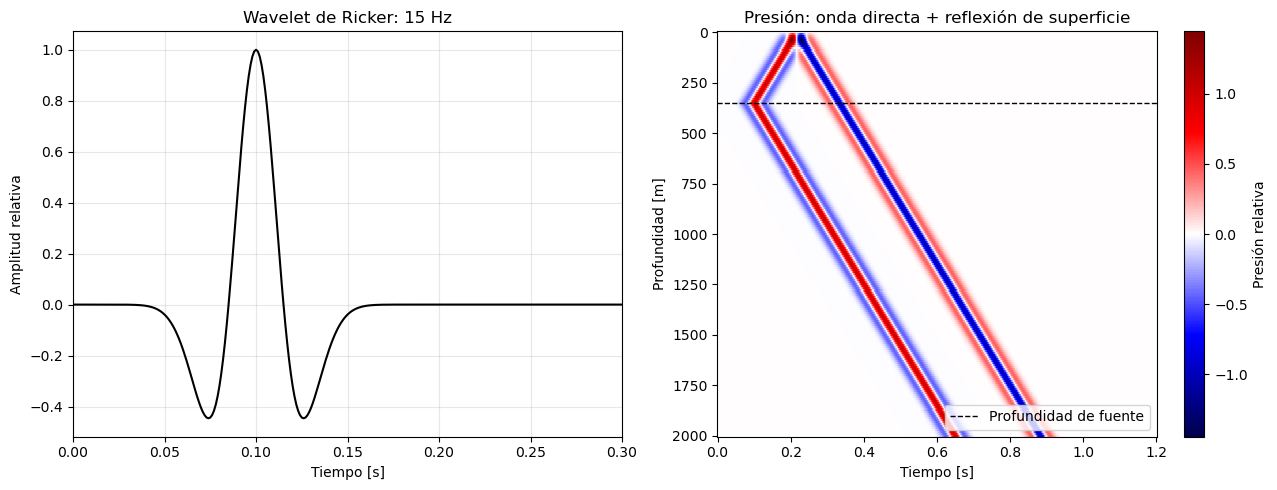

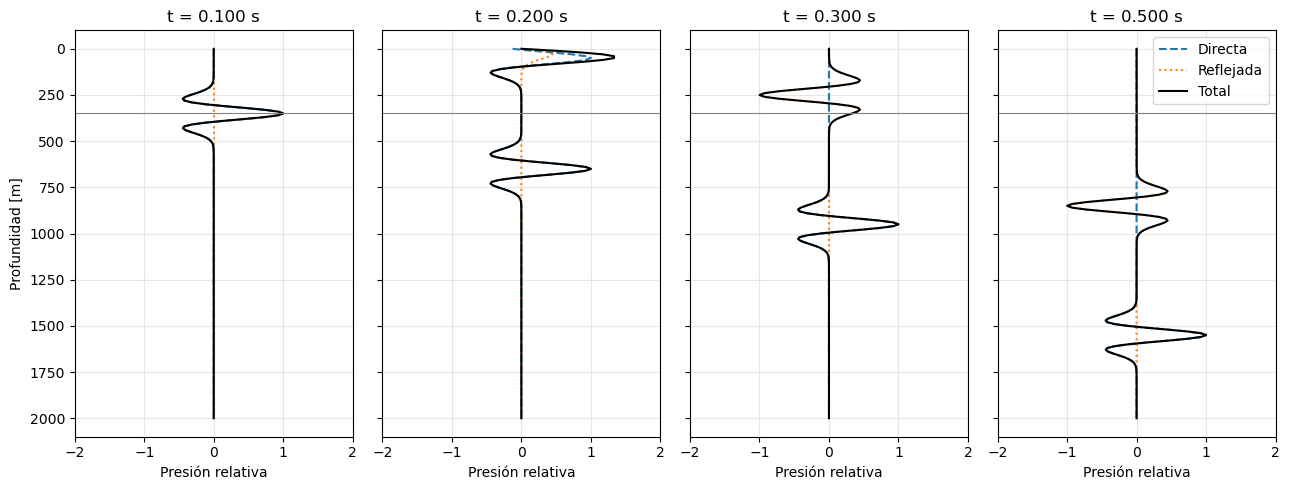

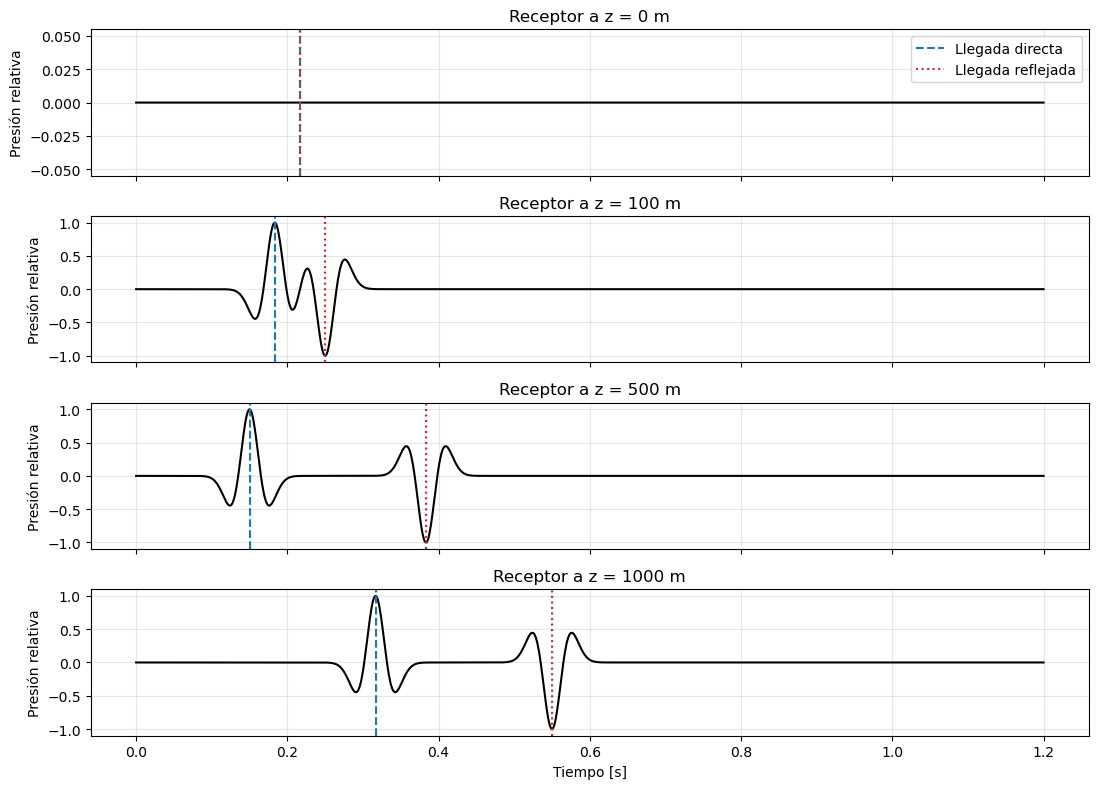

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Parámetros
# ============================================================
c = 3000.0       # Velocidad homogénea [m/s]
f0 = 15.0        # Frecuencia central de Ricker [Hz]
dh = 10.0        # Espaciado para representar el campo [m]
dt = 0.001       # Intervalo temporal [s]

z_source = 350.0 # Profundidad de la fuente [m]
z_max = 2000.0   # Profundidad máxima representada [m]
t_max = 1.2      # Tiempo máximo [s]

amplitude = 1.0  # Amplitud relativa
t0 = 1.5 / f0   # Retardo del máximo de Ricker [s]

z = np.arange(0.0, z_max + dh / 2, dh)
t = np.arange(0.0, t_max + dt / 2, dt)

# ============================================================
# 2. Wavelet de Ricker
# ============================================================
def ricker(tau, f0=15.0, t0=0.1):
    a = (np.pi * f0 * (tau - t0))**2
    return (1.0 - 2.0 * a) * np.exp(-a)

# ============================================================
# 3. Solución analítica: onda directa y fuente imagen
# ============================================================
# Broadcasting:
# Z tiene forma (Nz, 1); T tiene forma (1, Nt).
Z = z[:, None]
T = t[None, :]

travel_direct = np.abs(Z - z_source) / c
travel_reflected = (Z + z_source) / c

p_direct = amplitude * ricker(T - travel_direct, f0, t0)
p_reflected = -amplitude * ricker(T - travel_reflected, f0, t0)

# Campo total: forma (Nz, Nt)
p = p_direct + p_reflected

print(f"Campo de presión: {p.shape} = (profundidad, tiempo)")
print(f"Retardo de la fuente: {t0:.3f} s")
print(f"Máximo |p| en superficie: {np.max(np.abs(p[0])):.3e}")

# ============================================================
# 4. Wavelet y campo de presión
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(t, amplitude * ricker(t, f0, t0), color="black")
axes[0].set(
    title=f"Wavelet de Ricker: {f0:g} Hz",
    xlabel="Tiempo [s]",
    ylabel="Amplitud relativa",
    xlim=(0, 0.3),
)
axes[0].grid(alpha=0.3)

vmax = np.max(np.abs(p))
mesh = axes[1].pcolormesh(
    t, z, p,
    shading="auto",
    cmap="seismic",
    vmin=-vmax,
    vmax=vmax,
)
axes[1].axhline(
    z_source, color="black", linestyle="--",
    linewidth=1, label="Profundidad de fuente",
)
axes[1].invert_yaxis()
axes[1].set(
    title="Presión: onda directa + reflexión de superficie",
    xlabel="Tiempo [s]",
    ylabel="Profundidad [m]",
)
axes[1].legend(loc="lower right")
fig.colorbar(mesh, ax=axes[1], label="Presión relativa")

plt.tight_layout()
plt.show()

# ============================================================
# 5. Perfiles de presión a diferentes tiempos
# ============================================================
snapshot_times = [0.10, 0.20, 0.30, 0.50]
fig, axes = plt.subplots(
    1, len(snapshot_times),
    figsize=(13, 5),
    sharey=True,
)

for ax, requested_time in zip(axes, snapshot_times):
    it = np.argmin(np.abs(t - requested_time))

    ax.plot(p_direct[:, it], z, "--", label="Directa")
    ax.plot(p_reflected[:, it], z, ":", label="Reflejada")
    ax.plot(p[:, it], z, color="black", label="Total")

    ax.axhline(z_source, color="gray", linewidth=0.8)
    ax.set(
        title=f"t = {t[it]:.3f} s",
        xlabel="Presión relativa",
        xlim=(-2 * amplitude, 2 * amplitude),
    )
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Profundidad [m]")
axes[0].invert_yaxis()
axes[-1].legend()

plt.tight_layout()
plt.show()

# ============================================================
# 6. Trazas en receptores
# ============================================================
receiver_depths = [0.0, 100.0, 500.0, 1000.0]
fig, axes = plt.subplots(
    len(receiver_depths), 1,
    figsize=(11, 8),
    sharex=True,
)

for ax, receiver_depth in zip(axes, receiver_depths):
    iz = np.argmin(np.abs(z - receiver_depth))
    actual_depth = z[iz]

    ax.plot(t, p[iz], color="black")

    # Llegadas de los máximos de las wavelets
    direct_arrival = t0 + abs(actual_depth - z_source) / c
    reflected_arrival = t0 + (actual_depth + z_source) / c

    ax.axvline(
        direct_arrival, color="tab:blue",
        linestyle="--", label="Llegada directa",
    )
    ax.axvline(
        reflected_arrival, color="tab:red",
        linestyle=":", label="Llegada reflejada",
    )

    ax.set(
        title=f"Receptor a z = {actual_depth:g} m",
        ylabel="Presión relativa",
    )
    ax.grid(alpha=0.3)

axes[0].legend(loc="upper right")
axes[-1].set_xlabel("Tiempo [s]")

plt.tight_layout()
plt.show()

Modelo: (70, 201) = (Nx, Nz)
Fuente: ix=35, iz=30
Posición: x=350 m, z=300 m
Perfil: (201, 1201) = (Nz, Nt)
Máximo |p| en superficie: 0.0


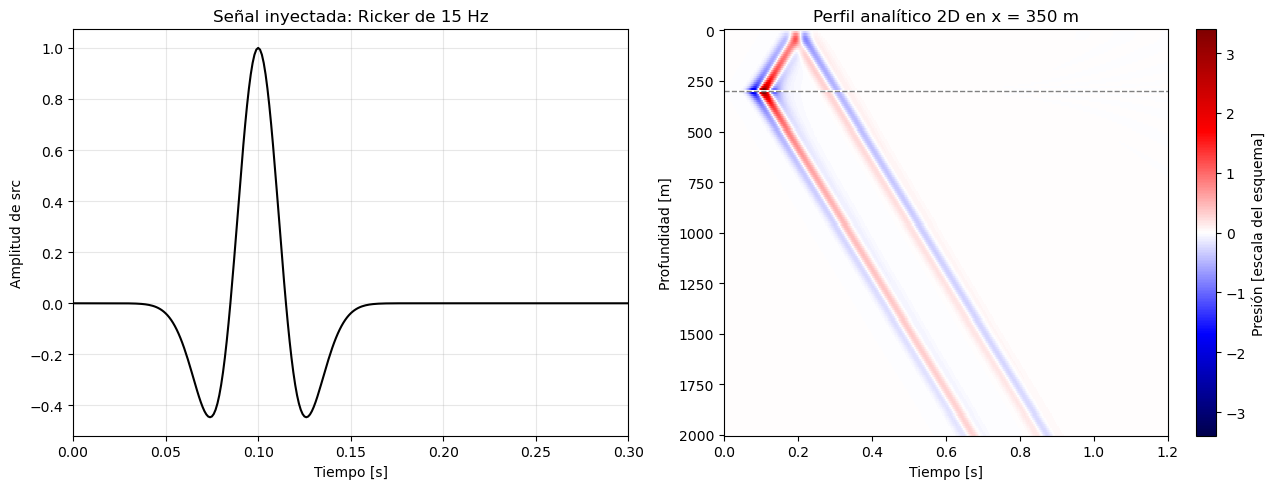

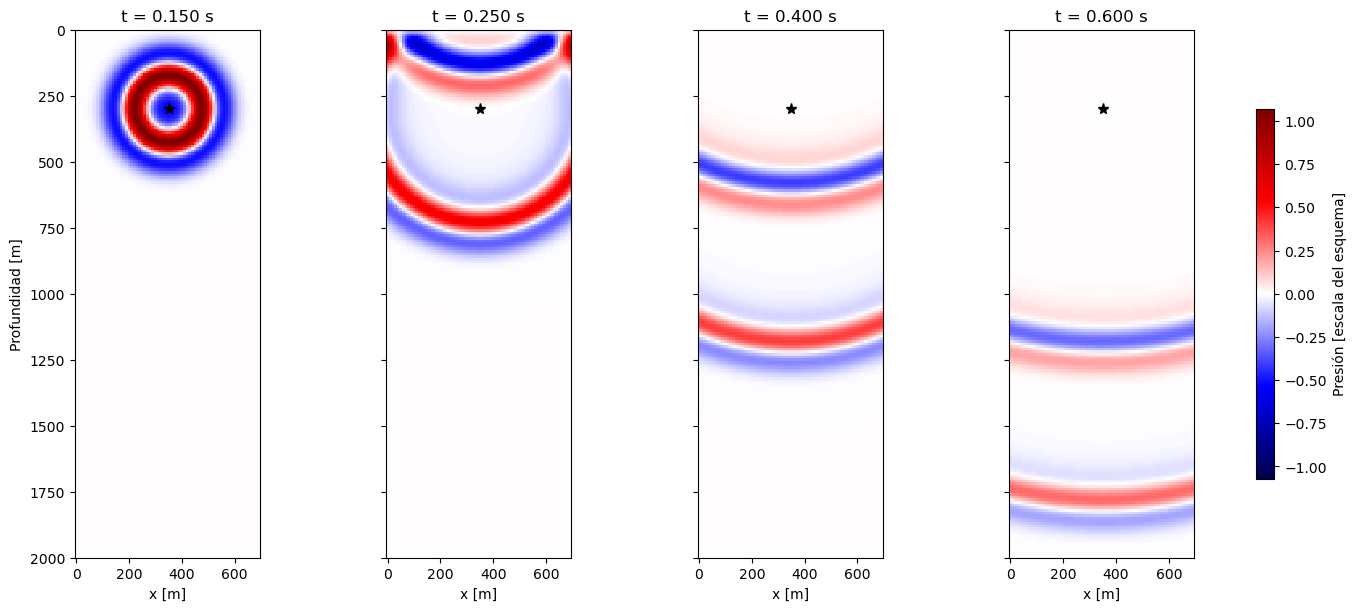

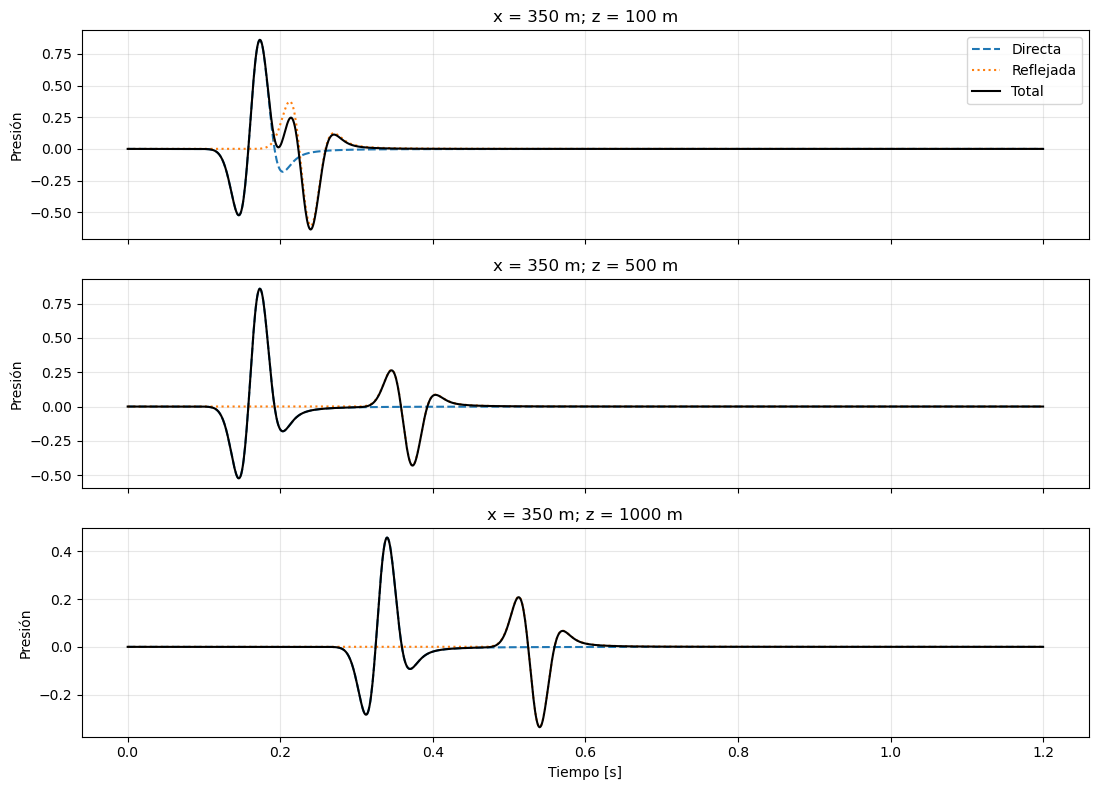

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.polynomial.legendre import leggauss

# ============================================================
# 1. Parámetros y modelo homogéneo
# ============================================================
c = 1500.0       # [m/s] 1500, 2000, 2500 3000, 3500, 4000, 4500
f0 = 15.0       # [Hz]
dh = 10.0       # [m]
dt = 0.001      # [s]

nx = 70
z_max = 2000.0
t_max = 1.2
z_source = 300.0

x = np.arange(nx) * dh
z = np.arange(0.0, z_max + dh / 2, dh)
t = np.arange(0.0, t_max + dt / 2, dt)

nz = len(z)
nt = len(t)

# Hay dos columnas centrales: escogemos la de la derecha.
ix_source = nx // 2
iz_source = int(round(z_source / dh))

x_source = x[ix_source]
z_source = z[iz_source]

# Orden consistente con P[Ix, Iz, it]
velocity = np.full((nx, nz), c)

print(f"Modelo: {velocity.shape} = (Nx, Nz)")
print(f"Fuente: ix={ix_source}, iz={iz_source}")
print(f"Posición: x={x_source:g} m, z={z_source:g} m")

# ============================================================
# 2. Fuente de Ricker causal
# ============================================================
t0 = 1.5 / f0
amplitude = 1.0

def ricker(time):
    time = np.asarray(time)
    a = (np.pi * f0 * (time - t0))**2
    wavelet = amplitude * (1.0 - 2.0 * a) * np.exp(-a)
    return np.where(time >= 0.0, wavelet, 0.0)

src = ricker(t)

# Para el esquema:
#
# P_new = 2*P - P_old + c**2 * dt**2 * laplaciano(P)
# P_new[ix_source, iz_source] += src[it_new]
#
# la fuente continua equivalente es:
# s(t) = (dh**2 / dt**2) * src(t)
#
# Esto usa delta_2D ≈ delta_nodo / dh**2.
# Cambiar si tu esquema utiliza otra normalización.
source_scale = dh**2 / dt**2

# ============================================================
# 3. Respuesta de una fuente puntual en 2D
# ============================================================
# La convolución causal es:
#
# p(r,t) = 1/(2*pi*c**2) *
#          integral desde r/c hasta t de
#          s(t-v) / sqrt(v**2 - (r/c)**2) dv
#
# Sustitución v = (r/c)*cosh(u):
# elimina la singularidad integrable del frente de onda.
#
# El punto r=0 es singular para una fuente puntual ideal.
# Lo dejamos como NaN, sin regularizarlo artificialmente.

n_quad = 96
nodes, weights = leggauss(n_quad)

def point_response(distances, times):
    """
    distances: array de distancias [m], con cualquier forma.
    times: array 1D de tiempos [s].

    Salida: distances.shape + (len(times),).
    """
    distances = np.asarray(distances, dtype=float)
    times = np.atleast_1d(times).astype(float)

    spatial_shape = distances.shape
    travel = distances.ravel() / c

    result = np.zeros((travel.size, len(times)))
    singular = (travel == 0.0)
    result[singular, :] = np.nan

    prefactor = source_scale / (2.0 * np.pi * c**2)

    for it, time in enumerate(times):
        active = (travel > 0.0) & (time > travel)
        if not np.any(active):
            continue

        a = travel[active]
        u_max = np.arccosh(time / a)

        # Cuadratura de Gauss-Legendre en [0, u_max]
        u = 0.5 * u_max[:, None] * (nodes[None, :] + 1.0)
        emission_time = time - a[:, None] * np.cosh(u)

        integral = (
            0.5 * u_max
            * np.sum(
                ricker(emission_time) * weights[None, :],
                axis=1,
            )
        )

        result[active, it] = prefactor * integral

    return result.reshape(spatial_shape + (len(times),))


def pressure_free_surface(X, Z, times):
    """Presión directa menos contribución de la fuente imagen."""
    X, Z = np.broadcast_arrays(X, Z)

    r_direct = np.sqrt(
        (X - x_source)**2 + (Z - z_source)**2
    )
    r_image = np.sqrt(
        (X - x_source)**2 + (Z + z_source)**2
    )

    direct = point_response(r_direct, times)
    reflected = -point_response(r_image, times)

    return direct + reflected, direct, reflected

# ============================================================
# 4. Perfil vertical en x = x_source
# ============================================================
p_profile, p_direct, p_reflected = pressure_free_surface(
    np.full_like(z, x_source),
    z,
    t,
)

# Forma: (Nz, Nt)
print(f"Perfil: {p_profile.shape} = (Nz, Nt)")
print(
    "Máximo |p| en superficie:",
    np.max(np.abs(p_profile[0])),
)

# ============================================================
# 5. Fuente y perfil profundidad-tiempo
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(t, src, color="black")
axes[0].set(
    title=f"Señal inyectada: Ricker de {f0:g} Hz",
    xlabel="Tiempo [s]",
    ylabel="Amplitud de src",
    xlim=(0, 0.3),
)
axes[0].grid(alpha=0.3)

vmax = np.nanmax(np.abs(p_profile))

mesh = axes[1].pcolormesh(
    t, z, np.ma.masked_invalid(p_profile),
    shading="auto",
    cmap="seismic",
    vmin=-vmax,
    vmax=vmax,
)

axes[1].axhline(
    z_source, color="gray", linestyle="--", linewidth=1
)
axes[1].invert_yaxis()
axes[1].set(
    title=f"Perfil analítico 2D en x = {x_source:g} m",
    xlabel="Tiempo [s]",
    ylabel="Profundidad [m]",
)
fig.colorbar(mesh, ax=axes[1], label="Presión [escala del esquema]")

plt.tight_layout()
plt.show()

# ============================================================
# 6. Imágenes del campo 2D a diferentes tiempos
# ============================================================
snapshot_times = np.array([0.15, 0.25, 0.40, 0.60])

X, Z = np.meshgrid(x, z, indexing="ij")
p_snapshots, _, _ = pressure_free_surface(X, Z, snapshot_times)

# Forma: (Nx, Nz, número de snapshots)
snapshot_vmax = np.nanmax(np.abs(p_snapshots))

fig, axes = plt.subplots(
    1, len(snapshot_times),
    figsize=(14, 6),
    sharey=True,
    constrained_layout=True,
)

for k, ax in enumerate(axes):
    mesh = ax.pcolormesh(
        x, z,
        np.ma.masked_invalid(p_snapshots[:, :, k].T),
        shading="auto",
        cmap="seismic",
        vmin=-snapshot_vmax,
        vmax=snapshot_vmax,
    )

    ax.plot(x_source, z_source, "k*", markersize=8)
    ax.set(
        title=f"t = {snapshot_times[k]:.3f} s",
        xlabel="x [m]",
        ylim=(z_max, 0),
    )
    ax.set_aspect("equal")

axes[0].set_ylabel("Profundidad [m]")
fig.colorbar(
    mesh, ax=axes.tolist(),
    label="Presión [escala del esquema]",
    shrink=0.7,
)
plt.show()

# ============================================================
# 7. Trazas en la columna de la fuente
# ============================================================
receiver_depths = [100.0, 500.0, 1000.0]

fig, axes = plt.subplots(
    len(receiver_depths), 1,
    figsize=(11, 8),
    sharex=True,
)

for ax, depth in zip(axes, receiver_depths):
    iz = np.argmin(np.abs(z - depth))

    ax.plot(t, p_direct[iz], "--", label="Directa")
    ax.plot(t, p_reflected[iz], ":", label="Reflejada")
    ax.plot(t, p_profile[iz], "k", label="Total")

    ax.set(
        title=f"x = {x_source:g} m; z = {z[iz]:g} m",
        ylabel="Presión",
    )
    ax.grid(alpha=0.3)

axes[0].legend()
axes[-1].set_xlabel("Tiempo [s]")

plt.tight_layout()
plt.show()

In [1]:
import numpy as np
from pathlib import Path
from numpy.polynomial.legendre import leggauss

# ============================================================
# 1. Parámetros
# ============================================================
velocities = np.array(
    [1500, 2000, 2500, 3000, 3500, 4000, 4500],
    dtype=float,
)

nx = 70
nz = 70
nt = 800

dh = 10.0       # [m]
dt = 0.001      # [s]
f0 = 15.0      # [Hz]
t0 = 1.5 / f0 # 0.1 equivalente
amplitude = 1.0

x = np.arange(nx) * dh
z = np.arange(nz) * dh
t = np.arange(nt) * dt

# Fuente en una de las dos columnas centrales y a 300 m.
ix_source = nx // 2
iz_source = nz // 2

x_source = x[ix_source]
z_source = z[iz_source]

# Misma normalización del código anterior:
# P_new[ix_source, iz_source] += src[it_new]
source_scale = dh**2 / dt**2

n_quad = 96
nodes, weights = leggauss(n_quad)

output_path = Path(
    "../../data/wavefields/analytical/wavefield_00.npy"
)
output_path.parent.mkdir(parents=True, exist_ok=True)

# ============================================================
# 2. Ricker causal
# ============================================================
def ricker(time):
    time = np.asarray(time)
    a = (np.pi * f0 * (time - t0))**2
    wavelet = amplitude * (1.0 - 2.0 * a) * np.exp(-a)
    return np.where(time >= 0.0, wavelet, 0.0)

# ============================================================
# 3. Distancias directa e imagen
# ============================================================
# Trabajamos en unidades de píxel para identificar exactamente
# las distancias repetidas.
IZ, IX = np.indices((nz, nx))

distance_squared_direct = (
    (IX - ix_source)**2 + (IZ - iz_source)**2
)
distance_squared_image = (
    (IX - ix_source)**2 + (IZ + iz_source)**2
)

# Una tabla común para ambas contribuciones.
unique_squared, inverse = np.unique(
    np.concatenate([
        distance_squared_direct.ravel(),
        distance_squared_image.ravel(),
    ]),
    return_inverse=True,
)

n_pixels = nz * nx

index_direct = inverse[:n_pixels].reshape(nz, nx)
index_image = inverse[n_pixels:].reshape(nz, nx)

distances = dh * np.sqrt(unique_squared.astype(float))

# ============================================================
# 4. Respuesta puntual 2D por distancia
# ============================================================
def response_by_distance(distances, times, c):
    """
    Devuelve un array (Nt, número de distancias).

    Integra la función de Green 2D mediante:
        v = (r/c) * cosh(u)

    La sustitución elimina la singularidad integrable
    del frente de onda para r > 0.
    """
    travel = distances / c

    response = np.zeros(
        (len(times), len(distances)),
        dtype=np.float64,
    )

    # La fuente puntual continua es singular en r = 0.
    singular = (distances == 0.0)
    response[:, singular] = np.nan

    prefactor = source_scale / (2.0 * np.pi * c**2)

    for it, time in enumerate(times):
        active = (travel > 0.0) & (time > travel)

        if not np.any(active):
            continue

        a = travel[active]
        u_max = np.arccosh(time / a)

        u = (
            0.5 * u_max[:, None]
            * (nodes[None, :] + 1.0)
        )

        emission_time = time - a[:, None] * np.cosh(u)

        integral = (
            0.5 * u_max
            * np.sum(
                ricker(emission_time) * weights[None, :],
                axis=1,
            )
        )

        response[it, active] = prefactor * integral

    return response

# ============================================================
# 5. Crear el archivo y calcular los siete cubos
# ============================================================
# Memmap escribe directamente en un archivo .npy válido.
# float32: aproximadamente 110 MB para el cubo completo.
shape = (len(velocities), nt, nz, nx)

wavefields = np.lib.format.open_memmap(
    output_path,
    mode="w+",
    dtype=np.float32,
    shape=shape,
)

for imodel, c in enumerate(velocities):
    print(
        f"Calculando modelo {imodel + 1}/{len(velocities)}: "
        f"c = {c:g} m/s",
        flush=True,
    )

    response = response_by_distance(distances, t, c)

    # Reconstrucción del campo:
    # (Nt, Nz, Nx), directa menos fuente imagen.
    field = (
        response[:, index_direct]
        - response[:, index_image]
    )

    # Verificar la condición de superficie libre.
    surface_error = np.max(np.abs(field[:, 0, :]))
    assert surface_error == 0.0

    # Únicamente el nodo de la fuente debe contener NaN.
    assert np.count_nonzero(np.isnan(field)) == nt

    wavefields[imodel] = field.astype(np.float32)
    wavefields.flush()

    print(
        f"  Guardado: {field.shape}; "
        f"máximo |p| en superficie = {surface_error:.3e}",
        flush=True,
    )

    del response, field

# Cerrar el acceso de escritura.
del wavefields

# ============================================================
# 6. Verificar el archivo guardado
# ============================================================
saved = np.load(output_path, mmap_mode="r")

assert saved.shape == (7, 800, 70, 70)
assert saved.dtype == np.float32

print(f"\nArchivo: {output_path}")
print(f"Forma: {saved.shape}")
print(f"Tipo: {saved.dtype}")
print(f"Tiempo: {t[0]:.3f} a {t[-1]:.3f} s")
print(f"Fuente: x={x_source:g} m, z={z_source:g} m")
print(f"Tamaño: {output_path.stat().st_size / 1e6:.1f} MB")

Calculando modelo 1/7: c = 1500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00
Calculando modelo 2/7: c = 2000 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00
Calculando modelo 3/7: c = 2500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00
Calculando modelo 4/7: c = 3000 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00
Calculando modelo 5/7: c = 3500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00
Calculando modelo 6/7: c = 4000 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00
Calculando modelo 7/7: c = 4500 m/s
  Guardado: (800, 70, 70); máximo |p| en superficie = 0.000e+00

Archivo: ../../data/wavefields/analytical/wavefield_00.npy
Forma: (7, 800, 70, 70)
Tipo: float32
Tiempo: 0.000 a 0.799 s
Fuente: x=350 m, z=350 m
Tamaño: 109.8 MB
